In [39]:
from doctest import debug, debug_script
from hashlib import algorithms_available
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
from skimage.restoration import unwrap_phase

# Point sys.path to the repository root
repo_root = Path.cwd().parent
if str(repo_root) not in sys.path:
    sys.path.append(str(repo_root))

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [40]:

# Import the PhaseMapGenerator (assuming you saved it in src/phase_map_generator.py)
# from src.phase_map_generator import PhaseMapGenerator
import config
import src.phase_extraction as pe
import src.calibration as calib
import src.slit_analysis as sa

# 30 bar

# Phase extraction at 90 degrees

In [57]:
hdf5_path = r"C:\Users\vmlab\Documents\data\files\2026\03\25\Ar-30bar"

roi = [2000, 5000, 1000, 4000]  # [x_start, x_end, y_start, y_end]
ref_img, exp_img, ref_roi, exp_roi = pe.get_interferometry_images(hdf5_path, roi=roi)


ref_fourier_shifted = pe.get_fourier(ref_roi)
exp_fourier_shifted = pe.get_fourier(exp_roi)

dominant_frequency = pe.get_dominant_frequency(ref_fourier_shifted, debug = False)

delta_phase_wrapped = pe.get_delta_phase_wrapped(ref_fourier_shifted, exp_fourier_shifted, dominant_frequency, debug = False)
ref_edge, *_ = calib.estimate_nozzle_edge(ref_roi)
x_left, x_right = calib.detect_nozzle_x_range(ref_roi, ref_edge)
calibrated_phase_perp, _ = calib.calibrate_phase(delta_phase_wrapped, ref_edge, x_left, x_right, debug = False)
calibrated_phase_perp = unwrap_phase(calibrated_phase_perp)


Unsupported data type for _convert.
Unsupported data type for _convert.


In [42]:
# Constants
NOZZLE_WIDTH_MM = 6.0
NOZZLE_OPENING_MM = 0.5
px_to_mm = calib.calculate_px_to_mm(x_left, x_right, NOZZLE_WIDTH_MM)

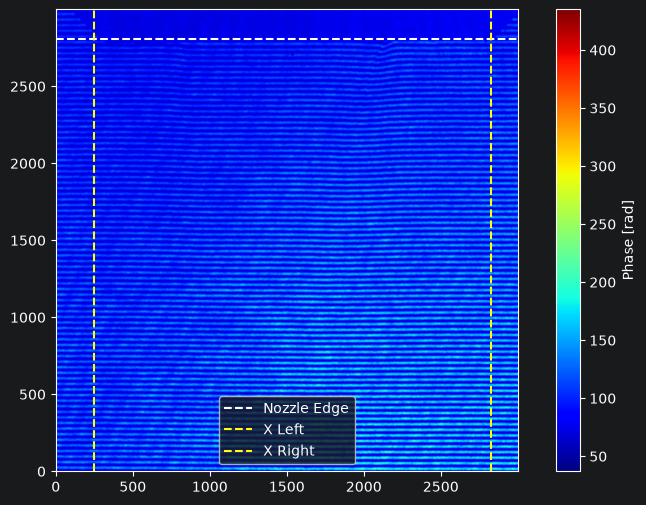

In [56]:
# show the calibrated phase map with the x range and nozzle edge
plt.figure(figsize=(10, 6))
plt.imshow(exp_roi, origin="lower", cmap="jet")
plt.axhline(ref_edge, color="white", linestyle="--", label="Nozzle Edge")
plt.axvline(x_left, color="yellow", linestyle="--", label="X Left")
plt.axvline(x_right, color="yellow", linestyle="--", label="X Right")
plt.colorbar(label="Phase [rad]")
plt.legend()
plt.show()

# Phase extraction at 0 degrees

In [44]:

hdf5_path = r"C:\Users\vmlab\Documents\data\files\2026\03\25\Ar-30bar 90deg"

roi = [2000, 5000, 1000, 4000]  # [x_start, x_end, y_start, y_end]
ref_img, exp_img, ref_roi, exp_roi = pe.get_interferometry_images(hdf5_path, roi=roi)

ref_fourier_shifted = pe.get_fourier(ref_roi)
exp_fourier_shifted = pe.get_fourier(exp_roi)

dominant_frequency = pe.get_dominant_frequency(ref_fourier_shifted, debug = False)

delta_phase_wrapped = pe.get_delta_phase_wrapped(ref_fourier_shifted, exp_fourier_shifted, dominant_frequency, debug = False)
ref_edge, *_ = calib.estimate_nozzle_edge(ref_roi)
x_left, x_right = calib.detect_nozzle_x_range(ref_roi, ref_edge)
calibrated_phase_para, _ = calib.calibrate_phase(delta_phase_wrapped, ref_edge, x_left, x_right, debug = False)


Unsupported data type for _convert.
Unsupported data type for _convert.


# density calculation

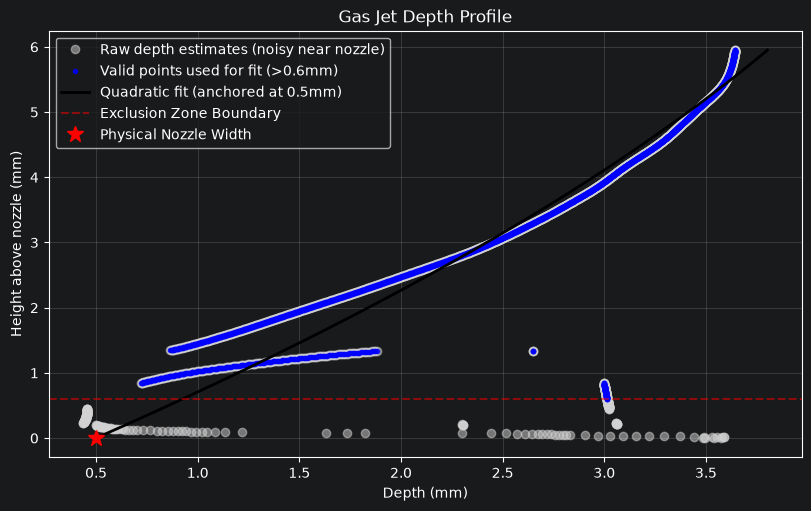

In [45]:
# Crop to 6mm and Flip (so y=0 is the nozzle edge)
phi_cropped = sa.crop_and_format_phase_map(
    calibrated_phase_para,
    nozzle_edge_y=ref_edge,
    px_to_mm=px_to_mm,
    max_height_mm=6.0
)

# Calculate Depth
y_mm_para, depth_fit_para, depth_debug = sa.estimate_depth_profile(
    phi_cropped,
    px_to_mm,
    nozzle_opening=NOZZLE_OPENING_MM,
    fit_type="quadratic_constrained",
    exclude_y_mm=0.6,
    debug_show=True,

)

In [48]:
# Convert to Density
cropped_phase_to_density = sa.crop_and_format_phase_map(
    calibrated_phase_perp,
    nozzle_edge_y=ref_edge-50,
    px_to_mm=px_to_mm,
    max_height_mm=6.0)
density_map, x_mm, y_mm = sa.phase_to_density(cropped_phase_to_density, px_to_mm, depth_y_mm=y_mm_para, depth_profile_mm=depth_fit_para, gas="argon")

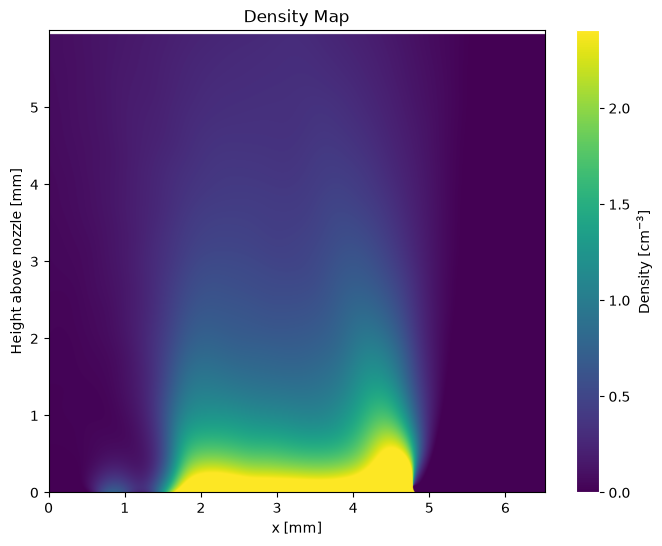

In [58]:

# Plot the result
fig, ax = plt.subplots(figsize=(8, 6), facecolor="white")
ax.set_facecolor("white")

m = np.nanpercentile(np.abs(density_map), 98.0)
extent = [x_mm[0], x_mm[-1], y_mm[0], y_mm[-1]]

im = ax.imshow(density_map, origin="lower", extent=extent, aspect="auto", cmap="viridis", vmin=0.0, vmax=m)

# Format title and axes for dark mode (force black text/ticks)
ax.set_title("Density Map", color="black")
ax.set_xlabel("x [mm]", color="black")
ax.set_ylabel("Height above nozzle [mm]", color="black")
ax.tick_params(colors="black")

# Force plot borders (spines) to be black
for spine in ax.spines.values():
    spine.set_color("black")

# Add and format the colorbar
cbar = fig.colorbar(im, ax=ax)
cbar.set_label("Density [cm$^{-3}$]", color="black")
cbar.ax.yaxis.set_tick_params(color="black") # Tick marks
plt.setp(plt.getp(cbar.ax.axes, 'yticklabels'), color='black') # Tick labels

plt.show()

Measured median Density at Exit:   3.34e+19 cm^-3
Theoretical De Laval Prediction: 4.33e+19 cm^-3
--------------------------------------------------
The 1D theoretical model overestimates the measured mean density by a factor of ~1.3x.


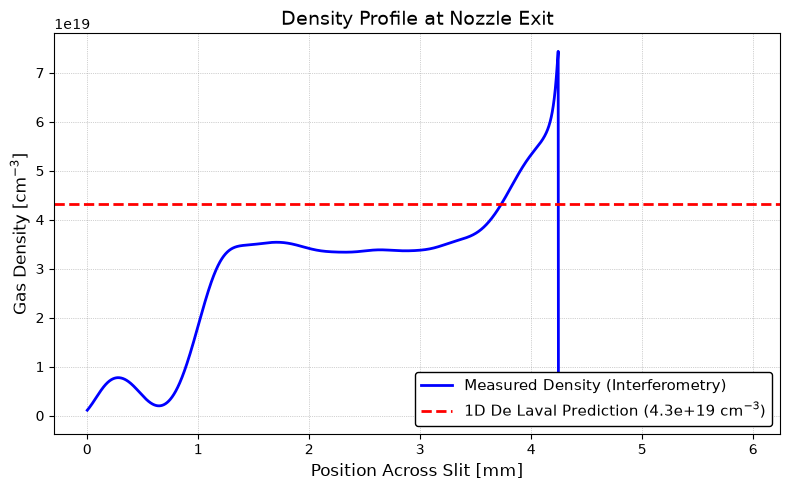

In [59]:
# --- Compare Measured vs. Theoretical Density at Nozzle Exit ---
import matplotlib.pyplot as plt
import numpy as np

# Since 'density_map' is already cropped to the region above the nozzle,
# the exit corresponds to the 0th row.
edge_z_pixel = 0

# Extract the horizontal lineout across the nozzle opening (between x_left and x_right)
measured_exit_lineout = density_map[edge_z_pixel, int(x_left):int(x_right)]

# Find the median measured density right at the exit
measured_median_density = np.median(measured_exit_lineout)

# Theoretical baseline calculated from 1D De Laval isentropic flow (30 bar backing pressure)
theoretical_peak_density = 4.33e19 # cm^-3

# Calculate the discrepancy ratio
ratio = theoretical_peak_density / measured_median_density

print(f"Measured median Density at Exit:   {measured_median_density:.2e} cm^-3")
print(f"Theoretical De Laval Prediction: {theoretical_peak_density:.2e} cm^-3")
print("-" * 50)
print(f"The 1D theoretical model overestimates the measured mean density by a factor of ~{ratio:.1f}x.")

# --- Plotting ---
# Create an x-axis in millimeters based on your previously defined px_to_mm
x_axis_mm = np.arange(len(measured_exit_lineout)) * px_to_mm

# Explicitly set the figure background to white
fig, ax = plt.subplots(figsize=(8, 5), facecolor="white")
ax.set_facecolor("white")

# Plot the empirical measurement
ax.plot(x_axis_mm, measured_exit_lineout, label="Measured Density (Interferometry)", color="blue", linewidth=2)

# Plot the theoretical prediction as a constant threshold
ax.axhline(y=theoretical_peak_density, color="red", linestyle="--", linewidth=2,
            label=f"1D De Laval Prediction ({theoretical_peak_density:.1e} cm$^{{-3}}$)")

# Formatting - Forcing colors to black for dark mode IDEs
ax.set_title("Density Profile at Nozzle Exit", fontsize=14, color="black")
ax.set_xlabel("Position Across Slit [mm]", fontsize=12, color="black")
ax.set_ylabel("Gas Density [cm$^{-3}$]", fontsize=12, color="black")
ax.tick_params(colors="black")

# Force the plot borders (spines) to be black
for spine in ax.spines.values():
    spine.set_color("black")

ax.grid(True, linestyle=":", alpha=0.7, color="gray")

# Place legend in the bottom right and force text to black
legend = ax.legend(loc="lower right", fontsize=11, facecolor="white", framealpha=1.0, edgecolor="black")
for text in legend.get_texts():
    text.set_color("black")

plt.tight_layout()
plt.show()